# California Housing: Predicting Median District House Values

## 1. Problem understanding

The target is a continuous numeric quantity, so this is **supervised regression**, not classification. The eight predictors are `MedInc` (median income), `HouseAge`, `AveRooms`, `AveBedrms`, `Population`, `AveOccup`, `Latitude`, and `Longitude`. We will predict `MedHouseVal`.

We will hold out a test set before fitting any preprocessing. A `Pipeline` will fit `StandardScaler` only on training data and then fit ordinary least squares Linear Regression. Scaling is useful for comparing coefficient magnitudes and for many other models; for unregularized ordinary least squares it generally does not change the fitted predictions (apart from numerical effects).

## 2. Load and understand the data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()
df = df.rename(columns={"MedHouseVal": "MedHouseVal"})
target = "MedHouseVal"
features = [column for column in df.columns if column != target]

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
print("Features:", features)
print("Target:", target, "(units of $100,000)")

Rows: 20,640 | Columns: 9
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target: MedHouseVal (units of $100,000)


In [3]:
display(df.head())
display(df.tail())
print("Shape:", df.shape)
df.info()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


Shape: (20640, 9)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


## 3. Exploratory data analysis

### Missing values and duplicate rows

In [5]:
missing = df.isna().sum().sort_values(ascending=False)
print("Missing values by column:")
display(missing.to_frame("missing_count"))
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

Missing values by column:


,missing_count
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


Exact duplicate rows: 0


There are no missing values in the source dataset in its usual release. If missing values appear in another version, investigate why; then impute inside the training pipeline (for example, with `SimpleImputer`) so the test set does not influence fitted preprocessing.

### Target distribution

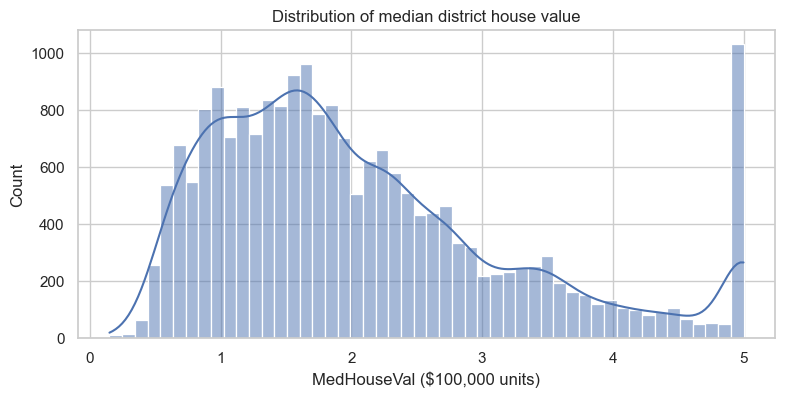

count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64
Share at the target cap (5.00001): 0.0468


In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df[target], bins=50, kde=True, ax=ax)
ax.set(title="Distribution of median district house value", xlabel="MedHouseVal ($100,000 units)")
plt.show()
print(df[target].describe())
print("Share at the target cap (5.00001):", (df[target] >= 5.00001).mean().round(4))

The target is right-skewed and top-coded at its upper bound. This means high-value predictions are compressed and errors in the highest-value districts need special care.

### Univariate feature distributions

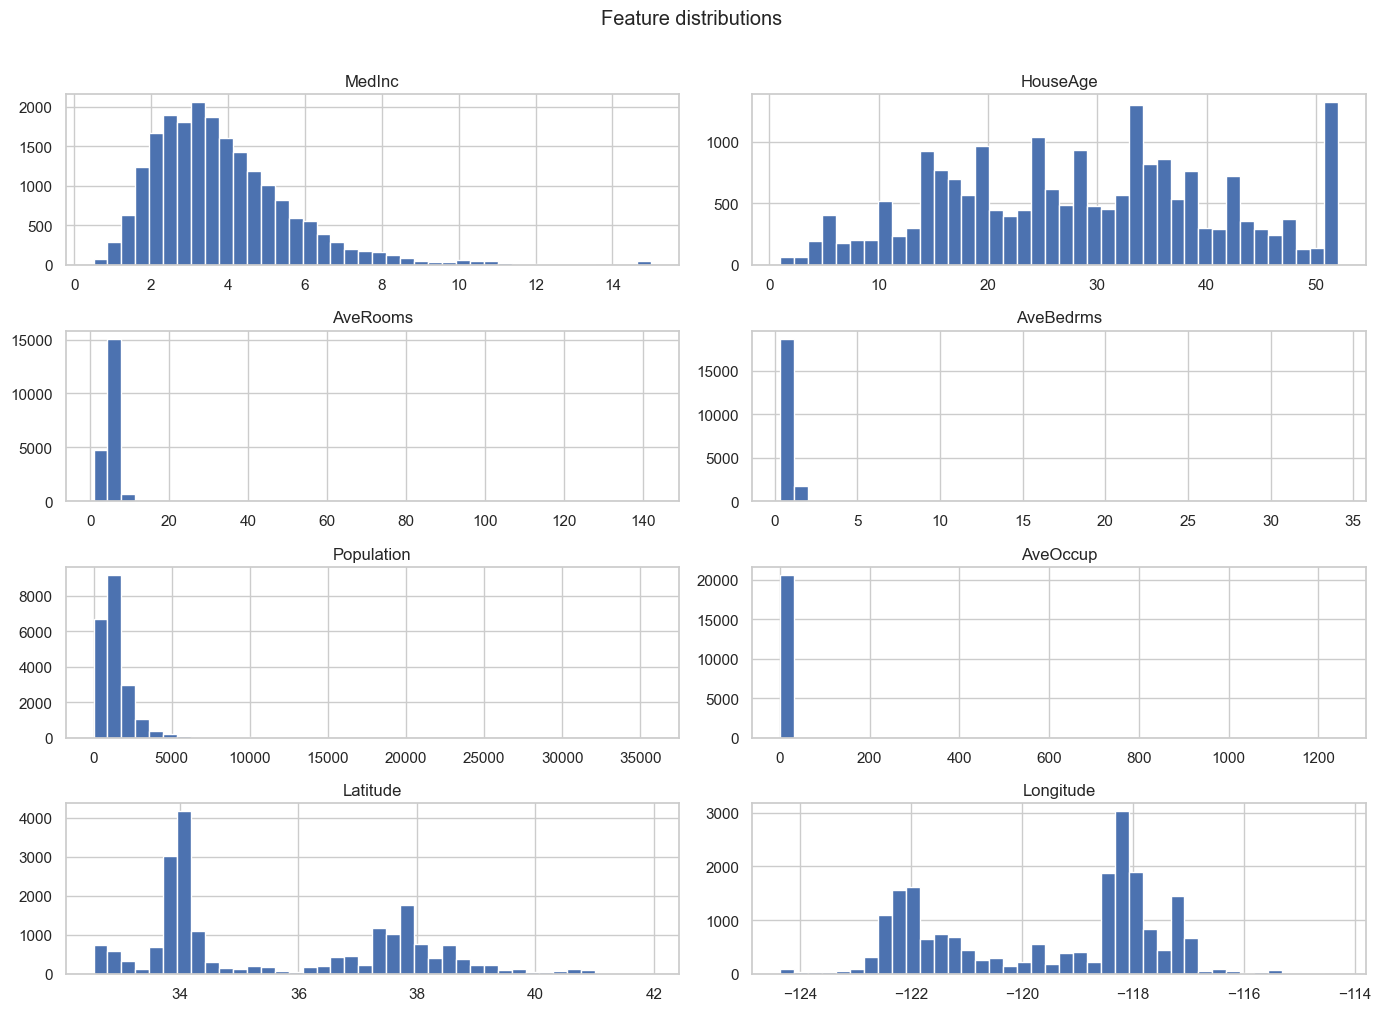

In [7]:
df[features].hist(bins=40, figsize=(14, 10), layout=(4, 2), edgecolor="white")
plt.suptitle("Feature distributions", y=1.01)
plt.tight_layout()
plt.show()

Several features are strongly skewed (for example, `AveOccup`) and some have extreme values. These observations may be legitimate districts rather than data errors; we will inspect them and keep them unless there is evidence of invalid records.

### Bivariate analysis

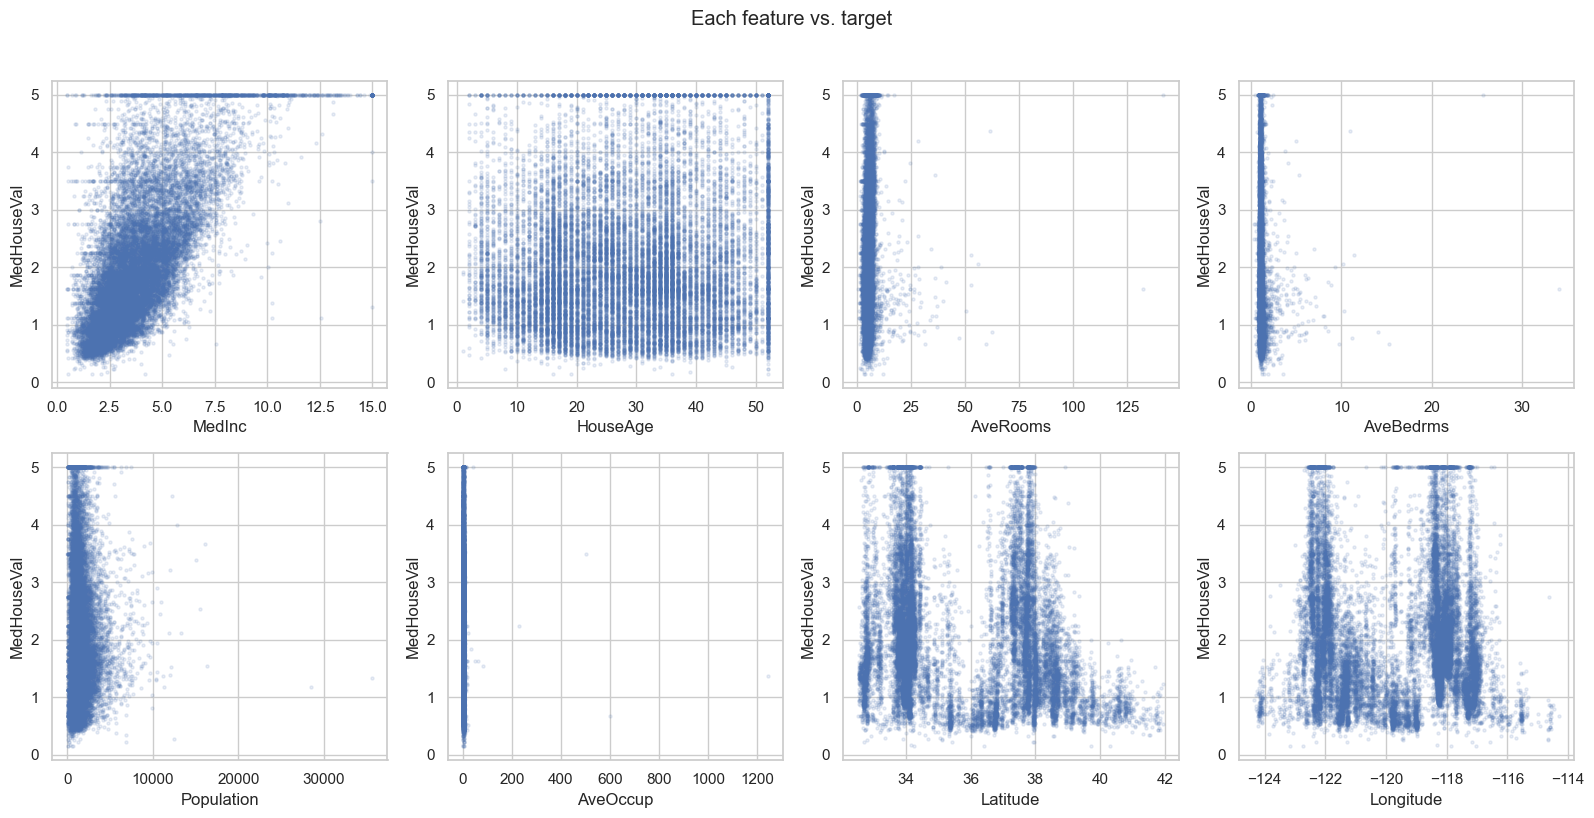

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, feature in zip(axes.flat, features):
    # A small alpha makes overlapping observations easier to see.
    ax.scatter(df[feature], df[target], s=5, alpha=0.12)
    ax.set_xlabel(feature)
    ax.set_ylabel("MedHouseVal")
fig.suptitle("Each feature vs. target", y=1.02)
plt.tight_layout()
plt.show()

### Correlations and potential multicollinearity

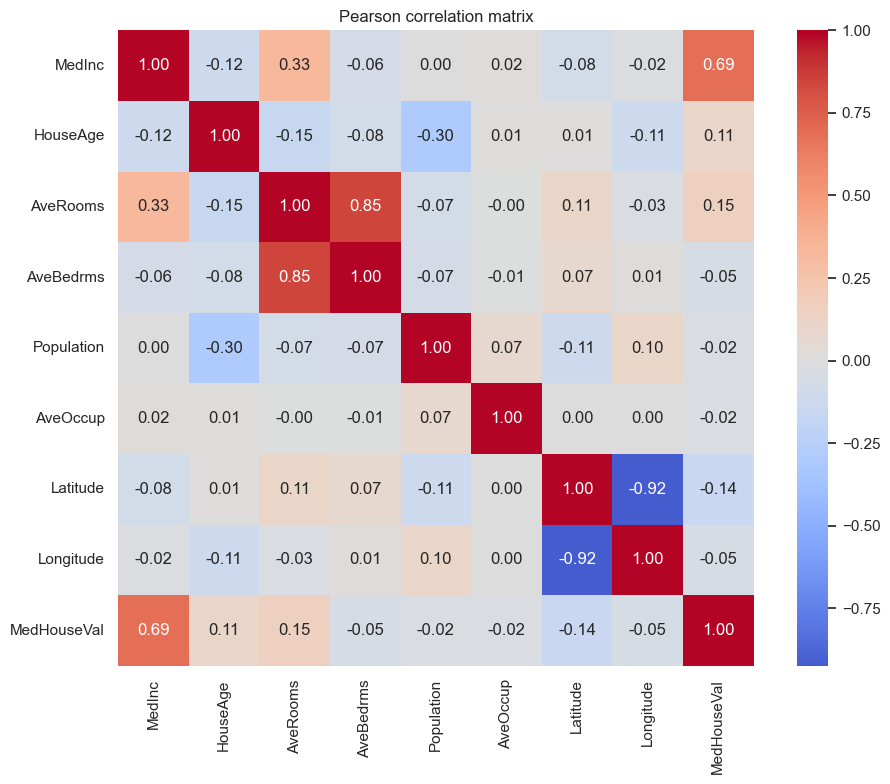

,correlation_with_target
MedInc,0.688075
AveRooms,0.151948
Latitude,-0.144160
HouseAge,0.105623
AveBedrms,-0.046701
Longitude,-0.045967
Population,-0.024650
AveOccup,-0.023737


In [9]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", square=True)
plt.title("Pearson correlation matrix")
plt.tight_layout()
plt.show()
display(corr[target].drop(target).sort_values(key=np.abs, ascending=False).to_frame("correlation_with_target"))

Pairwise correlations can flag redundancy, but they do not fully diagnose multicollinearity. Correlation is not causation, and a feature's coefficient in a multiple regression is a conditional association rather than a causal effect.

### Investigate extreme values

In [10]:
outlier_summary = []
for feature in features:
    q1, q3 = df[feature].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_summary.append({
        "feature": feature,
        "lower_fence": lower,
        "upper_fence": upper,
        "outside_fence_count": int(((df[feature] < lower) | (df[feature] > upper)).sum()),
    })
display(pd.DataFrame(outlier_summary).set_index("feature"))

,lower_fence,upper_fence,outside_fence_count
feature,,,
MedInc,-0.706375,8.013025,681
HouseAge,-10.500000,65.500000,0
AveRooms,2.023219,8.469878,511
AveBedrms,0.865909,1.239697,1424
Population,-620.000000,3132.000000,1196
AveOccup,1.150961,4.561041,711
Latitude,28.260000,43.380000,0
Longitude,-127.485000,-112.325000,0


The IQR rule is a flag for review, not an automatic deletion rule. For this project, retain valid extreme districts and report the target cap as a limitation. Robust regression, transformations, or geographic/temporal validation are reasonable later comparisons.

## 4–6. Prepare data, split, and scale without leakage

In [12]:
from sklearn.model_selection import train_test_split

X = df[features].copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"Train: {X_train.shape}; test: {X_test.shape}")

Train: (16512, 8); test: (4128, 8)


We split before fitting transformations because a scaler learns each feature's mean and standard deviation. Learning those values from all rows would let test-set information leak into training. The pipeline below handles this correctly.

## 7. Train Linear Regression

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model = make_pipeline(StandardScaler(), LinearRegression())
model.fit(X_train, y_train)

linear_regression = model.named_steps["linearregression"]
print("Intercept (target units):", linear_regression.intercept_)
coef = pd.Series(linear_regression.coef_, index=features, name="coefficient")
display(coef.reindex(coef.abs().sort_values(ascending=False).index).to_frame())

Intercept (target units): 2.071946937378881


,coefficient
Latitude,-0.896929
Longitude,-0.869842
MedInc,0.854383
AveBedrms,0.339259
AveRooms,-0.294410
HouseAge,0.122546
AveOccup,-0.040829
Population,-0.002308


Because the scaler transforms features to standard deviation units, each coefficient estimates the change in predicted target units for a one-standard-deviation increase in that feature, holding the other features fixed. Multiply a target-unit effect by $100,000 to express it in dollars. Coefficients can be unstable when predictors are correlated.

## 8. Evaluate training and test performance

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regression_metrics(estimator, X_part, y_part, split_name):
    pred = estimator.predict(X_part)
    mse = mean_squared_error(y_part, pred)
    return {
        "split": split_name,
        "MAE": mean_absolute_error(y_part, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_part, pred),
    }

metrics = pd.DataFrame([
    regression_metrics(model, X_train, y_train, "Train"),
    regression_metrics(model, X_test, y_test, "Test"),
]).set_index("split")
display(metrics)
print(f"Test MAE in dollars: ${metrics.loc['Test', 'MAE'] * 100_000:,.0f}")
print(f"Test RMSE in dollars: ${metrics.loc['Test', 'RMSE'] * 100_000:,.0f}")

,MAE,MSE,RMSE,R²
split,,,,
Train,0.528628,0.517933,0.719676,0.612551
Test,0.533200,0.555892,0.745581,0.575788


Test MAE in dollars: $53,320
Test RMSE in dollars: $74,558


MAE is the average absolute error and is easy to read in the target units. RMSE penalizes large errors more strongly. R² compares the model with predicting the test-set mean; it can be negative for a model worse than that baseline. Compare train and test scores for a rough generalization check, while remembering that a random split can place nearby districts in both sets.

## 9. Model diagnostics

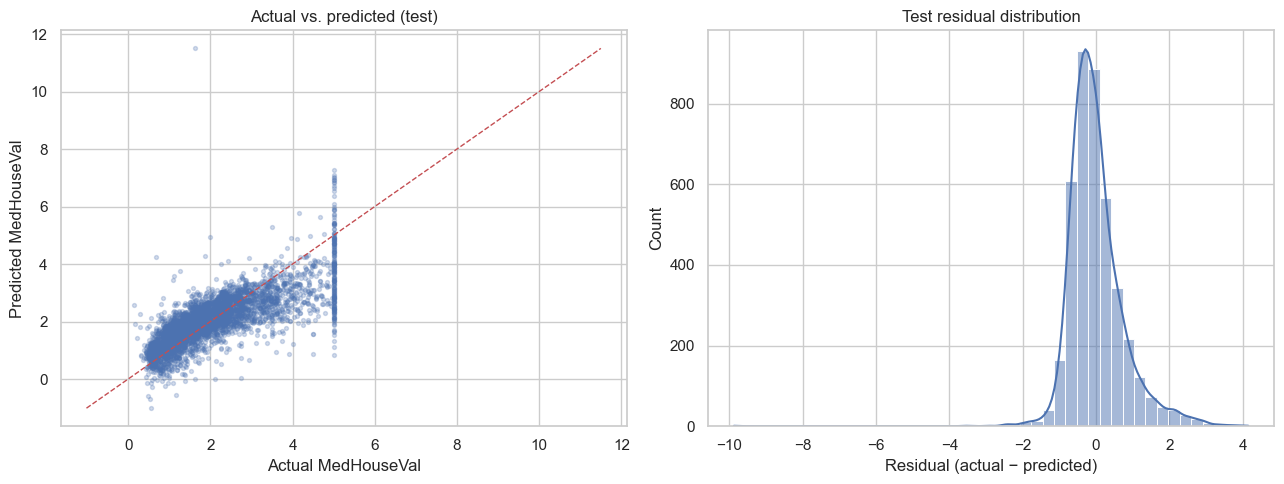

In [15]:
y_pred = model.predict(X_test)
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, y_pred, s=8, alpha=0.25)
lo = min(y_test.min(), y_pred.min())
hi = max(y_test.max(), y_pred.max())
axes[0].plot([lo, hi], [lo, hi], "r--", linewidth=1)
axes[0].set(xlabel="Actual MedHouseVal", ylabel="Predicted MedHouseVal", title="Actual vs. predicted (test)")
sns.histplot(residuals, bins=45, kde=True, ax=axes[1])
axes[1].set(xlabel="Residual (actual − predicted)", title="Test residual distribution")
plt.tight_layout()
plt.show()

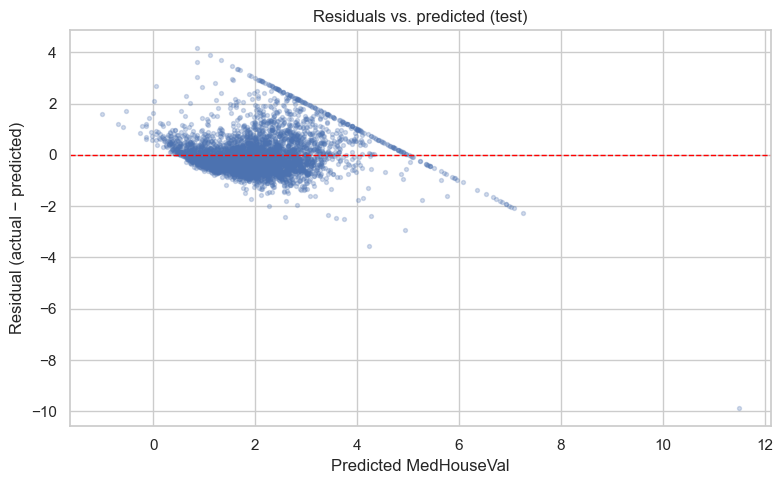

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, s=8, alpha=0.25)
plt.axhline(0, color="red", linestyle="--", linewidth=1)
plt.xlabel("Predicted MedHouseVal")
plt.ylabel("Residual (actual − predicted)")
plt.title("Residuals vs. predicted (test)")
plt.tight_layout()
plt.show()

Look for curvature, changing residual spread, clusters, and systematic under- or over-prediction. Linear regression assumes a useful linear form, independent errors, and (for classical inference) constant variance and well-behaved errors; diagnostics can reveal where the model is inadequate. The spatial structure of these data also challenges the random-split independence assumption.

## 10. Conclusions and next steps

In [ ]:
test_metrics = metrics.loc["Test"]
ranked = coef.reindex(coef.abs().sort_values(ascending=False).index)
print(f"Test R²: {test_metrics['R²']:.3f}")
print(f"Test MAE: {test_metrics['MAE']:.3f} target units (~${test_metrics['MAE'] * 100_000:,.0f})")
print("Largest standardized linear associations (by absolute coefficient):")
display(ranked.head(5).to_frame())

Test R²: 0.576
Test MAE: 0.533 target units (~$53,320)
Largest standardized linear associations (by absolute coefficient):


,coefficient
Latitude,-0.896929
Longitude,-0.869842
MedInc,0.854383
AveBedrms,0.339259
AveRooms,-0.294410


### Interpretation

- Use the coefficient table above to identify the largest conditional linear associations. They are predictive associations, not evidence that changing a feature causes a change in home value.
- Use the held-out metrics and diagnostic plots to judge performance. The metrics report error in units of $100,000, with dollar conversions shown for MAE and RMSE.
- The model is a simple linear baseline. It cannot represent nonlinear relationships or spatial interactions well, and the capped target limits high-value predictions. The data describe 1990 districts, not today's housing market; demographic and geographic features also raise fairness and privacy concerns if used for consequential decisions.

### Useful improvements

1. Compare with a median-predictor baseline and nonlinear models such as a random forest or gradient boosting.
2. Use cross-validation and a spatial or region-based holdout to test transfer to unseen areas.
3. Inspect errors by region and target range; report uncertainty and performance for relevant subgroups.
4. If the use case needs current prices, obtain recent, appropriately licensed data and retrain with a clearly defined prediction date.